# Fruit Ripeness Grader
Transfer-learning classifier (EfficientNet-B2) with cosine-annealing LR, early-stopping, and best-model checkpointing.

In [1]:
!pip install pillow pathlib torchvision tqdm torchsummary --quiet

In [2]:
import os
import random
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
%matplotlib inline

import torchvision.transforms as T
from torchvision import datasets, models
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import train_test_split
from torchsummary import summary
from PIL import Image
from tqdm import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


## Dataset Loading and Preprocessing

In [3]:
import sys
print(sys.executable)

/usr/bin/python3


## LOADING OF DATASET, EXPLORATORY ANALYSIS, AND SPLITTING (stratified)

In [4]:
ROOT = Path("/kaggle/input/datasets/maulidakiatuddin/fruit-ripeness-level/Fruit Ripeness Level Dataset1")  
IMG_SIZE, BATCH_SIZE, SEED = 224, 64, 42
NUM_WORKERS = 4

def seed_everything(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

seed_everything(SEED)

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted(d.name for d in ROOT.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(class_names)}
print(class_to_idx)

df = pd.DataFrame(
    [(str(p), class_to_idx[c]) for c in class_names
     for p in (ROOT / c).rglob("*") if p.suffix.lower() in EXTS],
    columns=["path", "label"],
)
print(len(class_names), "classes,", len(df), "images")

train_val, test_df = train_test_split(df, test_size=0.15, stratify=df.label, random_state=SEED)
train_df, val_df   = train_test_split(train_val, test_size=0.15 / 0.85,
                                      stratify=train_val.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

class FruitDS(Dataset):
    def __init__(self, df, tf):
        self.p, self.y, self.tf = df.path.tolist(), df.label.tolist(), tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

stats_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])
stats_loader = DataLoader(FruitDS(train_df, stats_tf),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

n_pix  = 0
ch_sum = torch.zeros(3, dtype=torch.float64)
ch_sq  = torch.zeros(3, dtype=torch.float64)
for x, _ in stats_loader:
    x = x.double()
    ch_sum += x.sum(dim=(0, 2, 3))
    ch_sq  += (x ** 2).sum(dim=(0, 2, 3))
    n_pix  += x.shape[0] * x.shape[2] * x.shape[3]

mean = ch_sum / n_pix
std  = (ch_sq / n_pix - mean ** 2).sqrt()
MEAN, STD = mean.float().tolist(), std.float().tolist()
print("train mean:", [round(m, 4) for m in MEAN],
      "| std:",      [round(s, 4) for s in STD])

norm = T.Normalize(MEAN, STD)

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    norm,
])
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), norm])

train_ds = FruitDS(train_df, train_tf)
val_ds   = FruitDS(val_df,   eval_tf)
test_ds  = FruitDS(test_df,  eval_tf)

kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
          pin_memory=True, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True,  drop_last=True, **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)

print(f"{len(train_ds)} train | {len(val_ds)} val | {len(test_ds)} test")

{'AppleRipe': 0, 'AppleRotten': 1, 'AppleUnripe': 2, 'BananaRipe': 3, 'BananaRotten': 4, 'BananaUnripe': 5, 'GrapeRipe': 6, 'GrapeRotten': 7, 'GrapeUnripe': 8, 'GuavaRipe': 9, 'GuavaRotten': 10, 'GuavaUnripe': 11, 'OrangeRipe': 12, 'OrangeRotten': 13, 'OrangeUnripe': 14, 'PomegranateRipe': 15, 'PomegranateRotten': 16, 'PomegranateUnripe': 17}
18 classes, 18330 images
train mean: [0.5804, 0.5632, 0.4132] | std: [0.3191, 0.3034, 0.3551]
12830 train | 2750 val | 2750 test


## MODEL DEFINITION

In [5]:
NUM_CLASSES = len(class_names)

model = models.efficientnet_b2(weights=models.EfficientNet_B2_Weights.DEFAULT)

in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3, inplace=True),
    nn.Linear(in_features, NUM_CLASSES),
)

model = model.to(DEVICE)

# summary (input shape: 3 × IMG_SIZE × IMG_SIZE)
summary(model, (3, IMG_SIZE, IMG_SIZE))

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 175MB/s] 


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 112, 112]             864
       BatchNorm2d-2         [-1, 32, 112, 112]              64
              SiLU-3         [-1, 32, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]             288
       BatchNorm2d-5         [-1, 32, 112, 112]              64
              SiLU-6         [-1, 32, 112, 112]               0
 AdaptiveAvgPool2d-7             [-1, 32, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             264
              SiLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 32, 1, 1]             288
          Sigmoid-11             [-1, 32, 1, 1]               0
SqueezeExcitation-12         [-1, 32, 112, 112]               0
           Conv2d-13         [-1, 16, 112, 112]             512
      BatchNorm2d-14         [-1, 16, 1

## TRAINING PROCESS — loss, optimiser, scheduler

In [6]:
EPOCHS        = 50
PATIENCE      = 7          
CHECKPOINT    = "/kaggle/working/best_model.pt"

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [7]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

def train_fn(model, device, train_loader, loss_fn, optimizer, epoch):
    model.train()
    train_loss, correct, total = 0.0, 0, 0          

    for data, target in tqdm(train_loader,         
                             desc=f"Train  Epoch {epoch+1}",
                             leave=False):
        data, target = data.to(device), target.to(device)

        # forward
        optimizer.zero_grad()
        output = model(data)
        loss   = loss_fn(output, target)

        # backward
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        total      += target.size(0)
        _, predicted = output.max(1)
        correct    += predicted.eq(target).sum().item()  

    avg_loss = train_loss / len(train_loader)
    accuracy = 100.0 * correct / total
    return avg_loss, accuracy

In [8]:
def eval_fn(model, loader, loss_fn, device, epoch=0, split="Val"):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0  

    with torch.no_grad():
        for data, target in tqdm(loader,
                                 desc=f"{split:5s} Epoch {epoch+1}",
                                 leave=False):
            data, target = data.to(device), target.to(device)  

            output = model(data)
            loss   = loss_fn(output, target)
            total_loss += loss.item()              
            _, pred = output.max(1)
            total   += target.size(0)
            correct += pred.eq(target).sum().item() 

    avg_loss = total_loss / len(loader)            
    accuracy = 100.0 * correct / total
    return avg_loss, accuracy

## TRAINING LOOP (with early stopping & best-model checkpoint)

In [9]:
best_val_loss   = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):
    train_loss, train_accuracy = train_fn(
        model, DEVICE, train_loader, criterion, optimizer, epoch
    )
    val_loss, val_accuracy = eval_fn(
        model, val_loader, criterion, DEVICE, epoch, split="Val"
    )
    
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_accuracy)

    print(
        f"Epoch {epoch+1:3d}/{EPOCHS}  "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.2f}%  " 
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.2f}%"
    )
# model checkpointing
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), CHECKPOINT)
        print(f" Best model saved  (val_loss={best_val_loss:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f" Early stopping triggered after {epoch+1} epochs.")
            break

print(f"\nTraining complete. Best val loss: {best_val_loss:.4f}")

Epoch   1/50  Train Loss: 0.6306 | Train Acc: 82.80%  Val Loss: 0.2105 | Val Acc: 93.35%
 Best model saved  (val_loss=0.2105)


Epoch   2/50  Train Loss: 0.1784 | Train Acc: 94.30%  Val Loss: 0.1412 | Val Acc: 95.82%
 Best model saved  (val_loss=0.1412)


Epoch   3/50  Train Loss: 0.1032 | Train Acc: 96.60%  Val Loss: 0.1332 | Val Acc: 96.00%
 Best model saved  (val_loss=0.1332)


Epoch   4/50  Train Loss: 0.0724 | Train Acc: 97.67%  Val Loss: 0.1248 | Val Acc: 96.25%
 Best model saved  (val_loss=0.1248)


Epoch   5/50  Train Loss: 0.0603 | Train Acc: 98.16%  Val Loss: 0.1002 | Val Acc: 97.09%
 Best model saved  (val_loss=0.1002)


Epoch   6/50  Train Loss: 0.0487 | Train Acc: 98.46%  Val Loss: 0.1059 | Val Acc: 97.31%


... (8 outputs left out)

Epoch  15/50  Train Loss: 0.0201 | Train Acc: 99.30%  Val Loss: 0.1099 | Val Acc: 97.56%


Epoch  16/50  Train Loss: 0.0136 | Train Acc: 99.53%  Val Loss: 0.1012 | Val Acc: 97.85%


Epoch  17/50  Train Loss: 0.0154 | Train Acc: 99.51%  Val Loss: 0.1136 | Val Acc: 97.78%


Epoch  18/50  Train Loss: 0.0141 | Train Acc: 99.52%  Val Loss: 0.0944 | Val Acc: 98.22%
 Early stopping triggered after 18 epochs.

Training complete. Best val loss: 0.0820


## LOSS & ACCURACY CURVES

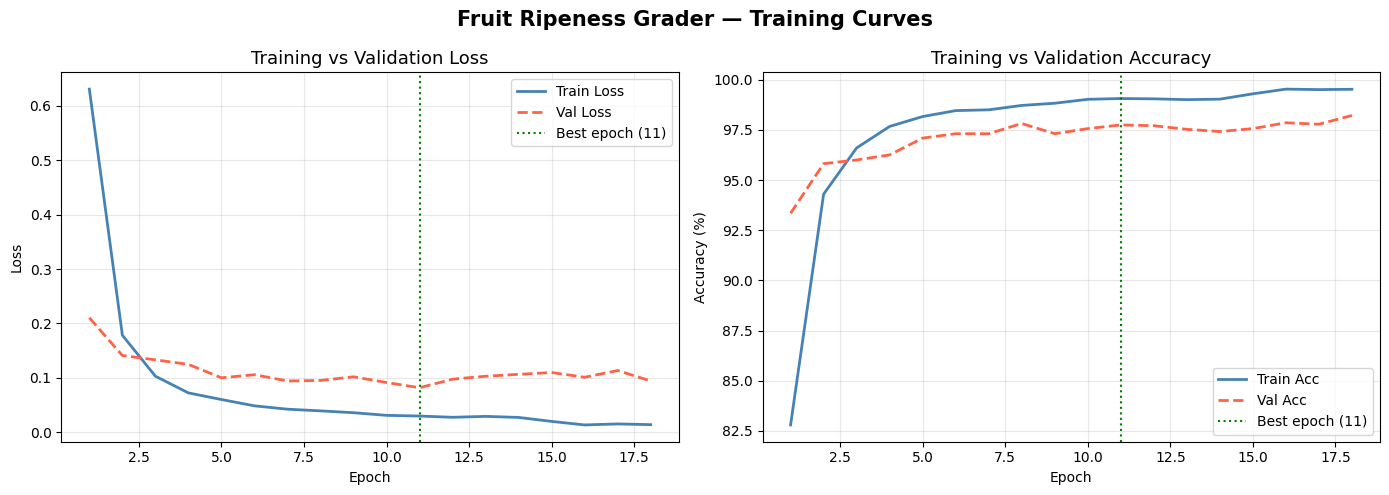

Saved → training_curves.png


In [10]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(epochs_ran, history["train_loss"], label="Train Loss",
        color="steelblue", linewidth=2)
ax.plot(epochs_ran, history["val_loss"],   label="Val Loss",
        color="tomato",    linewidth=2, linestyle="--")
best_epoch = history["val_loss"].index(min(history["val_loss"])) + 1
ax.axvline(best_epoch, color="green", linestyle=":", linewidth=1.5,
           label=f"Best epoch ({best_epoch})")
ax.set_title("Training vs Validation Loss", fontsize=13)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.3)

#accuracy
ax = axes[1]
ax.plot(epochs_ran, history["train_acc"], label="Train Acc",
        color="steelblue", linewidth=2)
ax.plot(epochs_ran, history["val_acc"],   label="Val Acc",
        color="tomato",    linewidth=2, linestyle="--")
ax.axvline(best_epoch, color="green", linestyle=":", linewidth=1.5,
           label=f"Best epoch ({best_epoch})")
ax.set_title("Training vs Validation Accuracy", fontsize=13)
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle("Fruit Ripeness Grader — Training Curves", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()
print("Saved → training_curves.png")

## TEST EVALUATION (best model checkpoint)

Testing: 100%|██████████| 43/43 [00:40<00:00,  1.06it/s]



  TEST RESULTS
  Loss     : 0.0686
  Accuracy : 98.36%

                   precision    recall  f1-score   support

        AppleRipe       0.99      1.00      0.99       150
      AppleRotten       1.00      0.98      0.99       150
      AppleUnripe       1.00      0.96      0.98       150
       BananaRipe       0.98      0.99      0.99       150
     BananaRotten       0.99      0.99      0.99       150
     BananaUnripe       1.00      0.99      1.00       150
        GrapeRipe       0.99      1.00      0.99       150
      GrapeRotten       0.98      0.98      0.98       166
      GrapeUnripe       0.99      0.97      0.98       151
        GuavaRipe       0.99      1.00      1.00       151
      GuavaRotten       0.97      0.99      0.98       150
      GuavaUnripe       0.98      0.97      0.98       170
       OrangeRipe       0.97      1.00      0.99       151
     OrangeRotten       0.99      0.97      0.98       151
     OrangeUnripe       0.94      0.97      0.96       15

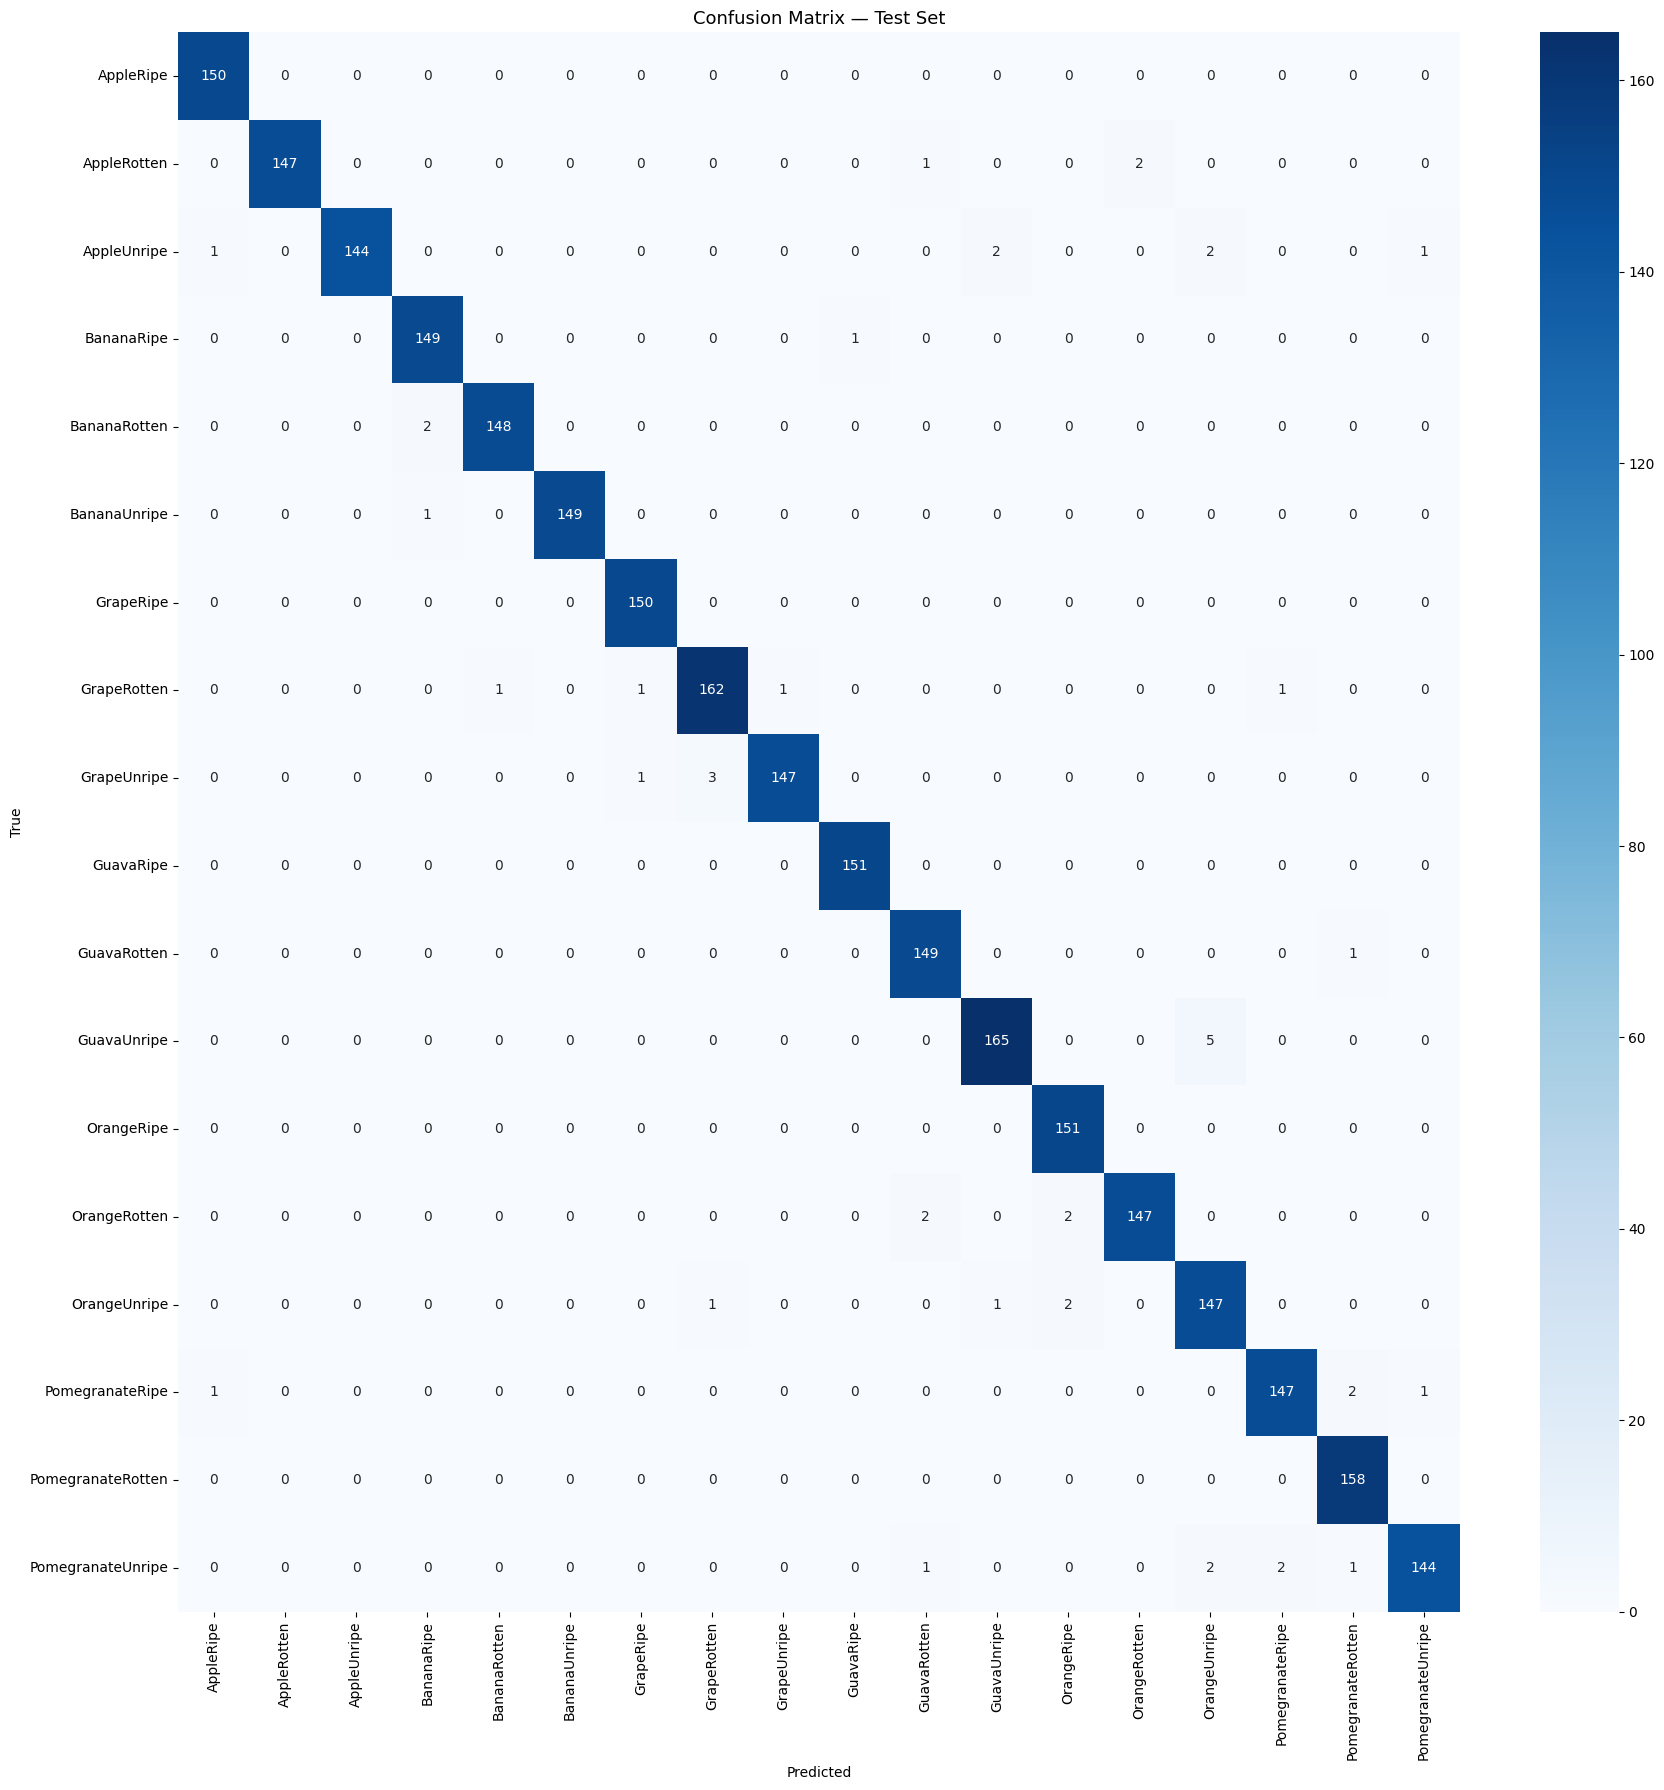

Saved → confusion_matrix.png


In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True))
model.eval()

all_preds, all_targets = [], []

with torch.no_grad():
    for data, target in tqdm(test_loader, desc="Testing"):
        data, target = data.to(DEVICE), target.to(DEVICE)
        output = model(data)
        _, pred = output.max(1)
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(target.cpu().numpy())

test_loss, test_accuracy = eval_fn(
    model, test_loader, criterion, DEVICE, epoch=0, split="Test"
)
print(f"\n{'='*55}")
print(f"  TEST RESULTS")
print(f"  Loss     : {test_loss:.4f}")
print(f"  Accuracy : {test_accuracy:.2f}%")
print(f"{'='*55}\n")

print(classification_report(all_targets, all_preds, target_names=class_names))

#confusin matrix
cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(max(6, len(class_names)), max(5, len(class_names))))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_title("Confusion Matrix — Test Set", fontsize=13)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("Saved → confusion_matrix.png")

## SAVE MODEL (local or Kaggle output)

In [12]:
import os, shutil

ON_KAGGLE = os.path.exists("/kaggle/working")
SAVE_DIR  = "/kaggle/working" if ON_KAGGLE else "."   # <- change "." to your local path
os.makedirs(SAVE_DIR, exist_ok=True)

full_ckpt_path = os.path.join(SAVE_DIR, "fruit_ripeness_full.pt")
torch.save(
    {
        "model_state_dict" : model.state_dict(),
        "optimizer_state"  : optimizer.state_dict(),
        "class_names"      : class_names,
        "class_to_idx"     : class_to_idx,
        "num_classes"      : NUM_CLASSES,
        "img_size"         : IMG_SIZE,
        "mean"             : MEAN,
        "std"              : STD,
        "best_val_loss"    : best_val_loss,
        "test_accuracy"    : test_accuracy,
        "history"          : history,
        "epochs_trained"   : len(history["train_loss"]),
    },
    full_ckpt_path,
)
print(f"Full checkpoint saved  -> {full_ckpt_path}")

# Save inference-only weights
weights_path = os.path.join(SAVE_DIR, "fruit_ripeness_weights.pt")
torch.save(model.state_dict(), weights_path)
print(f"Weights-only file saved -> {weights_path}")

# Copy training curves + confusion matrix to SAVE_DIR
for fig_name in ("training_curves.png", "confusion_matrix.png"):
    src = fig_name                             
    dst = os.path.join(SAVE_DIR, fig_name)
    if os.path.exists(src) and os.path.abspath(src) != os.path.abspath(dst):
        shutil.copy(src, dst)
        print(f"Figure copied          -> {dst}")
    elif os.path.exists(dst):
        print(f"Figure already at      -> {dst}")

# Environment-specific notes
if ON_KAGGLE:
    print("\n[Kaggle] All files in /kaggle/working/ will appear in the")
    print("         Output tab after the kernel finishes. Download them")
    print("         or add the output as a dataset for your next notebook.")
    print("         To push to Kaggle Models, run the cell below.")
else:
    print(f"\n[Local] Models saved to: {os.path.abspath(SAVE_DIR)}")


Full checkpoint saved  -> /kaggle/working/fruit_ripeness_full.pt
Weights-only file saved -> /kaggle/working/fruit_ripeness_weights.pt
Figure already at      -> /kaggle/working/training_curves.png
Figure already at      -> /kaggle/working/confusion_matrix.png

[Kaggle] All files in /kaggle/working/ will appear in the
         Output tab after the kernel finishes. Download them
         or add the output as a dataset for your next notebook.
         To push to Kaggle Models, run the cell below.


### (Optional) Push to Kaggle Models via API
> Run this cell only on Kaggle. Requires your notebook to have **Internet enabled**.

In [ ]:
if ON_KAGGLE:
    KAGGLE_USERNAME = "your-kaggle-username"   
    MODEL_SLUG      = "fruit-ripeness-grader"
    FRAMEWORK       = "pytorch"
    INSTANCE_SLUG   = "efficientnet-b2" 

    model_dir = "/kaggle/working/kaggle_model_upload"
    os.makedirs(model_dir, exist_ok=True)

    # Copy the weights into the upload folder
    shutil.copy(weights_path, os.path.join(model_dir, "model.pt"))

    # Write model-instance metadata
    import json as _json
    meta = {
        "title"           : "Fruit Ripeness Grader",
        "id"              : f"{KAGGLE_USERNAME}/{MODEL_SLUG}",
        "licenses"        : [{"name": "Apache 2.0"}],
    }
    with open(os.path.join(model_dir, "model-metadata.json"), "w") as f:
        _json.dump(meta, f, indent=2)

    os.system(
        f"kaggle models instances versions create {model_dir} "
        f"--framework {FRAMEWORK} "
        f"--overview \"EfficientNet-B2 trained on Fruit Ripeness Level Dataset.\" "
        f"--model {KAGGLE_USERNAME}/{MODEL_SLUG} "
        f"--instance {KAGGLE_USERNAME}/{MODEL_SLUG}/{FRAMEWORK}/{INSTANCE_SLUG}"
    )
    print("Model pushed to Kaggle Models.")
else:
    print("Skipped — not running on Kaggle.")
